In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu, threshold_niblack, threshold_sauvola

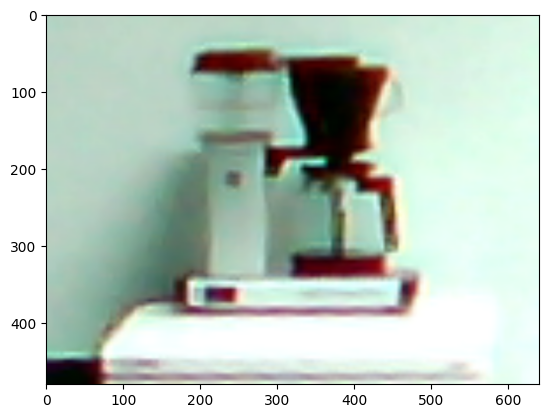

In [2]:
img = cv2.imread('test_image.png')
plt.imshow(img)

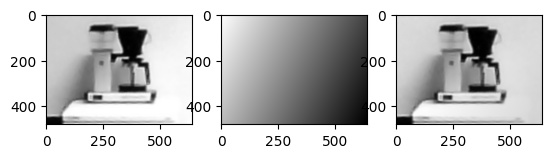

In [3]:
# Grayscale
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.subplot(1, 3, 1)
plt.imshow(img_gray, cmap='gray')
#plt.show()

def linear_illumination(x, y, w):
    return w[0] + w[1]*x + w[2]*y

N, M = img_gray.shape
# Taking a slice from top left corner
se_median = np.median(img_gray[N-50:N, M-50:M].ravel())
nw_median = np.median(img_gray[0:50, 0:50].ravel())
ne_median = np.median(img_gray[0:50, M-50:M].ravel())

# Linear illumination filter
I = np.zeros((N, M))
for i in range(N):
    for j in range(M):
        I[i, j] = linear_illumination(i, j, [nw_median, -(se_median - ne_median)/N, -(ne_median - nw_median)/M])

# Min-Max normalization
I = (I) / 255

img_gray = img_gray * I
# normalize
img_gray = 255*(img_gray - np.min(img_gray)) / (np.max(img_gray) - np.min(img_gray))
img_gray = img_gray.astype(np.uint8)
plt.subplot(1, 3, 2)
plt.imshow(I, cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow(img_gray, cmap='gray')

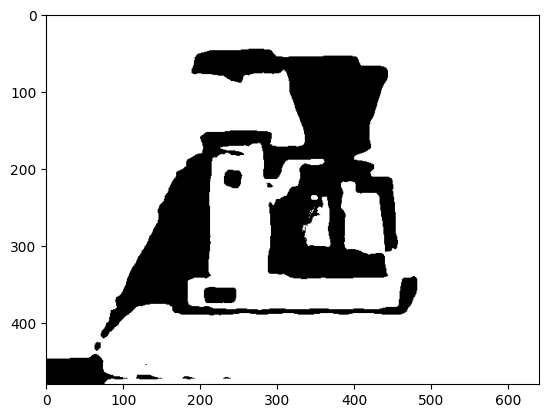

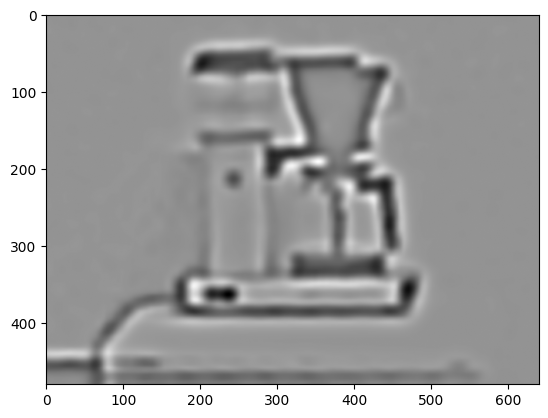

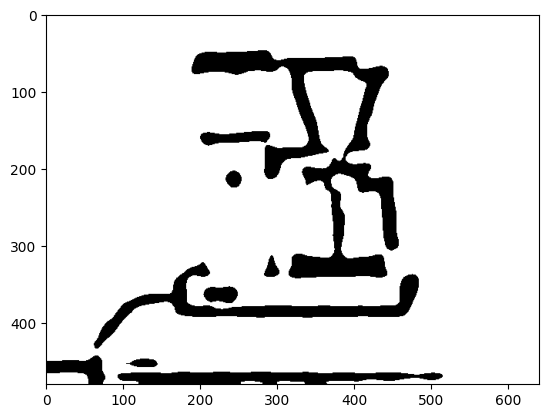

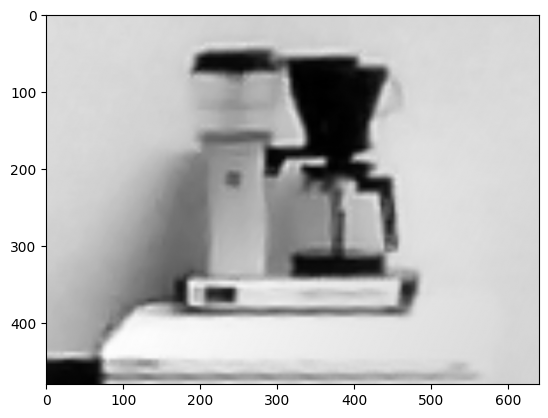

In [55]:
img_otsu = img_gray > threshold_otsu(img_gray)
plt.imshow(img_otsu, cmap='gray')
plt.show()
img_new = difference_of_gaussians(img_gray, .05, 10)
img_sauvola = threshold_niblack(img_new, window_size=15, k=0.2)
#minmax
img_sauvola = (img_sauvola - np.min(img_sauvola)) / (np.max(img_sauvola) - np.min(img_sauvola))
plt.imshow(img_sauvola, cmap='gray')
plt.show()
img_otsu = img_sauvola > threshold_otsu(img_sauvola)
plt.imshow(img_otsu, cmap='gray')
plt.show()

plt.imshow(img_gray, cmap='gray')
plt.show()

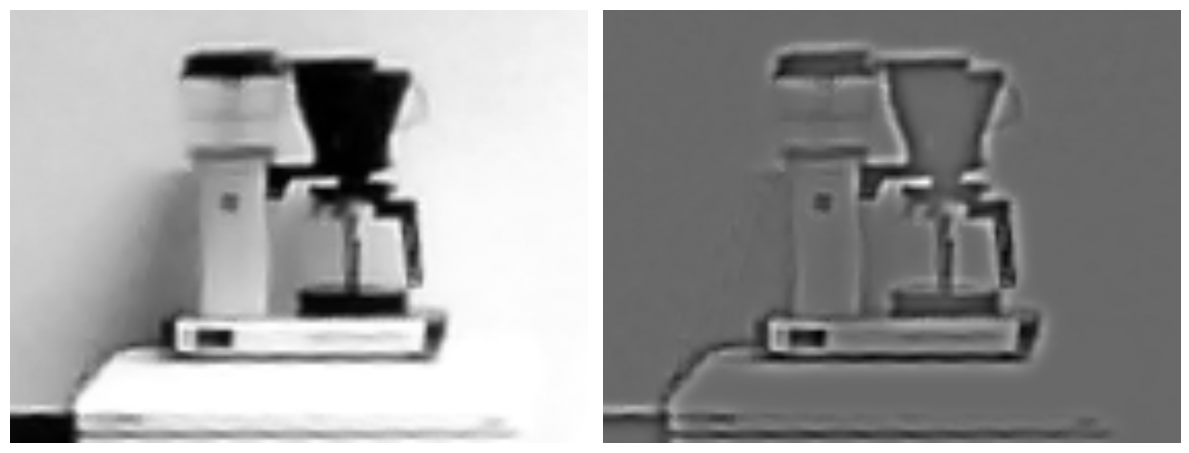

In [21]:
from skimage.filters import difference_of_gaussians
from skimage.color import rgb2gray   
import matplotlib.pylab as plt

im = rgb2gray(plt.imread('test_image.png')) # convert to grayscale image
im = im / im.max() # normalize
im_filtered = difference_of_gaussians(im, 0.05, 10.0) # choose suitable low & high sigmas
im_filtered = im_filtered / im_filtered.max()

plt.figure(figsize=(12,8))
plt.subplot(121), plt.imshow(im, cmap='gray'), plt.axis('off')
plt.subplot(122), plt.imshow(im_filtered, cmap='gray'), plt.axis('off')
plt.tight_layout()
plt.show()

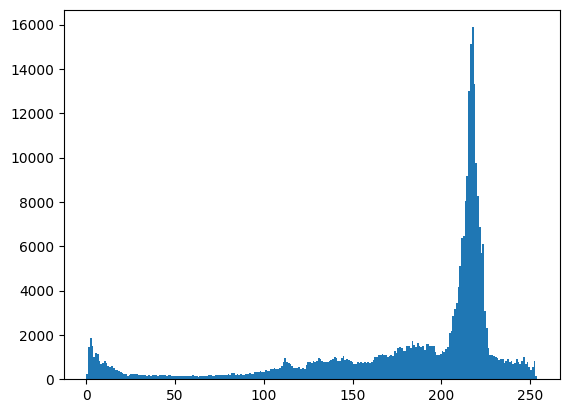

In [159]:
img_median = cv2.medianBlur(img_gray, 5)
x = plt.hist(img_median.ravel(), 255)

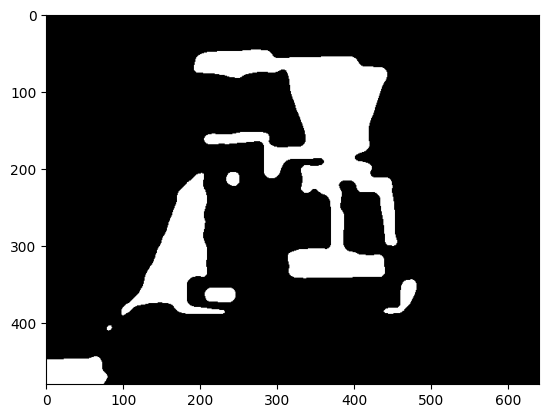

In [160]:
T1 = 120
T2 = 200

img_threshold = np.zeros_like(img_median)
img_threshold[img_median < T1] = 0
img_threshold[img_median > T1] = 255

plt.imshow(img_median<T1, cmap='gray')